# Detecção e classificação de crimes cibernéticos em redes sociais utilizando algoritmos de aprendizado de máquina

**Alunos:**

Caio Vinícius Cunha Bernardo - *Nro. USP: 14652143*

Lucas Neves Souza - *Nro. USP: 15577627*

Willian Jefferson Sousa Farias - *Nro. USP: 15642665*

---

## Notebook 2 de 3: dataset de 13 rótulos (Multilabel)

Reúne a **análise exploratória** e o **modelo em cascata** para o dataset multirrótulo, além das análises do modelo (ROC-AUC, matrizes de confusão, *self-attention*) e da ablação da perda ponderada.

**Projeto em três notebooks**

1. `1_Dois_Rotulos.ipynb`: análise exploratória e cascata (SVM + BERTimbau) no dataset **Binary** (`aggressive`, `hate`).
2. `2_Treze_Rotulos.ipynb` **(este notebook)**: análise exploratória e cascata no dataset **Multilabel** (13 rótulos), com ROC-AUC, matrizes de confusão, atenção e ablação da perda ponderada.
3. `3_Simulacao_Oliveira.ipynb`: baselines de estágio único para reproduzir os resultados de Oliveira et al. (2024) e compará-los com a cascata.

Os notebooks 1 e 2 gravam os resultados da cascata na pasta `resultados/`, que o notebook 3 lê para as comparações. Rode na ordem 1 → 2 → 3; o notebook 3 também roda sozinho, e nesse caso as comparações com a cascata são ignoradas.

# Setup

Primeiramente, realizamos a instalação das bibliotecas pelo terminal. Vamos instalar a biblioteca do **Hugging Face** (transformers), os *datasets* do Hugging Face e a ferramenta de otimização (accelerate), exigida pelo `Trainer`. As demais bibliotecas (pandas, scikit-learn, PyTorch, matplotlib, seaborn) já vêm instaladas no Google Colab.

1) Hugging Face: plataforma open-source onde desenvolvedores compartilham e colaboram em modelos de aprendizado de máquina, *datasets* e outras ferramentas de IA.

In [22]:
!pip install -q transformers accelerate datasets

Vamos importar as bibliotecas necessárias para a nossa programação:

1) O **pandas** é uma biblioteca de código aberto para a linguagem Python focada em manipulação e análise de dados;
2) O **Scikit-learn** (também conhecido como sklearn) é uma biblioteca de código aberto para a linguagem Python voltada para o aprendizado de máquina e modelagem estatística (Fase 1: TF-IDF + SVM);
3) O **PyTorch** é uma biblioteca usada principalmente para inteligência artificial, aprendizado de máquina e aprendizado profundo;
4) **matplotlib** e **seaborn** serão usadas na Análise Exploratória.

Embora o pandas seja excelente para manipular planilhas e visualizar os textos, os modelos de rede neural pesada processam dados em blocos vetoriais (Tensores). A biblioteca **datasets** converte DataFrames do Pandas para um formato de memória que a GPU consegue consumir muito mais rápido.

Além disso, no Deep Learning, o treinamento ocorre em épocas, exige cálculo de perda, ajuste na taxa de aprendizado e controle do tamanho do lote. As classes **Trainer** e **TrainingArguments** abstraem toda essa engenharia para que possamos treinar o BERT usando poucas linhas.

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
from datasets import Dataset

# Fase 1 (Scikit-learn)
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import train_test_split

# Fase 2 (Hugging Face e PyTorch)
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    EarlyStoppingCallback,
    Trainer,
    TrainingArguments,
    set_seed,
)

SEED = 42
set_seed(SEED)

# Verificar se a GPU foi reconhecida pelo PyTorch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Processamento rodando em: {device}")

Processamento rodando em: cuda


O fluxo final será: o **Scikit-learn** faz a triagem inicial (Fase 1: há ou não crime), o **pandas** e o **Dataset** organizam os textos, e o **Trainer** ajusta os pesos do modelo **BERT** para classificar as categorias (Fase 2).

Por fim, definimos o modelo pré-treinado (BERTimbau, versão *base*, mais leve que a *large*) e carregamos seu *tokenizer*, que será usado na Fase 2:

In [24]:
MODEL_NAME = "neuralmind/bert-base-portuguese-cased"
tokenizer_bert = AutoTokenizer.from_pretrained(MODEL_NAME)

# Importando Dataset pelo GitHub

Vamos fazer a importação dos arquivos **.csv** do [repositório original](https://github.com/Silly-Machine/TuPyE-Expanded-Brazilian-Hate-Speech-Dataset).

In [25]:
# Colunas que não serão úteis para o treinamento (rede social, pesquisador e ano)
COLUNAS_DESCARTADAS = ['source', 'researcher', 'year']

BASE_URL = ("https://raw.githubusercontent.com/Silly-Machine/"
            "TuPyE-Expanded-Brazilian-Hate-Speech-Dataset/refs/heads/master")

# Multilabel
df_multilabel_train = pd.read_csv(f"{BASE_URL}/multilabel/multilabel_train.csv")
df_multilabel_test = pd.read_csv(f"{BASE_URL}/multilabel/multilabel_test.csv")

Vamos unificar as duas partes (treino e teste) do dataset para realizarmos a **análise exploratória**:

In [26]:
# ignore_index=True evita índices duplicados (treino e teste ambos começam em 0)
df_multilabel_full = pd.concat([df_multilabel_train, df_multilabel_test], ignore_index=True)

# Análise Exploratória do Dataset Multilabel

Vamos analisar as cinco primeiras linhas do DataFrame **Multilabel**

In [27]:
df_multilabel_full.head()

,text,aggressive,hate,ageism,aporophobia,body_shame,capacitism,lgbtphobia,political,racism,religious_intolerance,misogyny,xenophobia,other,researcher,year,source
0,realidade: trabalha fdp,1,0,0,0,0,0,0,0,0,0,0,0,1,leite et al,2020,twitter
1,[2/8 1:24 pm] terezinha: carol n茫o 茅 processo\...,0,0,0,0,0,0,0,0,0,0,0,0,0,leite et al,2020,twitter
2,Lula inocente,0,0,0,0,0,0,0,0,0,0,0,0,0,vargas et al,2021,instagram
3,Imagino que o Senhor Jesus esteja decepcionado...,0,0,0,0,0,0,0,0,0,0,0,0,0,vargas et al,2021,instagram
4,@user bom dia !,0,0,0,0,0,0,0,0,0,0,0,0,0,oliveira et al,2023,twitter


Como a referência a respeito dos pesquisadores responsáveis por cada dado e rotulações (researcher), o ano (year) e a rede social de origem (source) não serão úteis para o treinamento do modelo, começaremos os ajustes no DataFrame a partir da remoção dessas colunas.

In [28]:
# Realizando a retirada das colunas "researcher", "year" e "source"
df_multilabel_cleaned = df_multilabel_full.drop(columns=COLUNAS_DESCARTADAS)
df_multilabel_cleaned.head()

,text,aggressive,hate,ageism,aporophobia,body_shame,capacitism,lgbtphobia,political,racism,religious_intolerance,misogyny,xenophobia,other
0,realidade: trabalha fdp,1,0,0,0,0,0,0,0,0,0,0,0,1
1,[2/8 1:24 pm] terezinha: carol n茫o 茅 processo\...,0,0,0,0,0,0,0,0,0,0,0,0,0
2,Lula inocente,0,0,0,0,0,0,0,0,0,0,0,0,0
3,Imagino que o Senhor Jesus esteja decepcionado...,0,0,0,0,0,0,0,0,0,0,0,0,0
4,@user bom dia !,0,0,0,0,0,0,0,0,0,0,0,0,0


Para revelar o grau exato de **desbalanceamento** do DataSet, vamos realizar a **plotagem** da frequência absoluta das classes.

Para isso, basta realizar um somatório para cada um dos rótulos e, depois, imprimir um gráfico de barras que demonstre a frequência de cada um.

In [29]:
# O texto, aqui, não será útil
df_multilabel_frequency = df_multilabel_cleaned.drop(columns='text')

# Realizando somatório para cada coluna
col_sum_multilabel = df_multilabel_frequency.sum()

print(col_sum_multilabel)

aggressive               11272
hate                      5252
ageism                      57
aporophobia                 66
body_shame                 285
capacitism                  99
lgbtphobia                 805
political                 1150
racism                     290
religious_intolerance      108
misogyny                  1675
xenophobia                 357
other                     4477
dtype: int64


Com isso, vamos realizar a primeira plotagem:

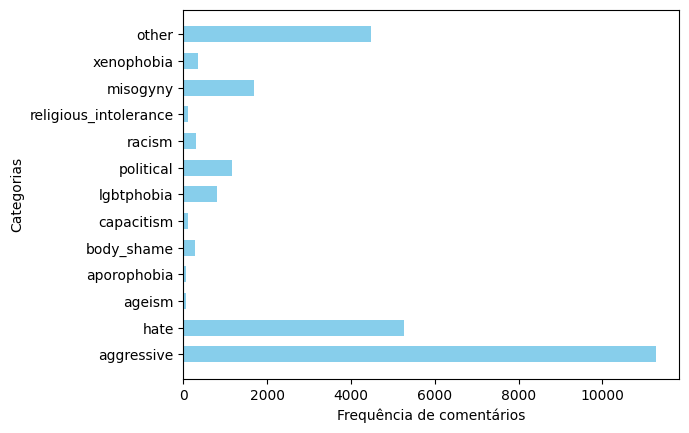

In [30]:
# Passando argumentos para a função de barra horizontal
plt.barh(col_sum_multilabel.index.tolist(), col_sum_multilabel.values, color='skyblue', height=0.6)

plt.xlabel("Frequência de comentários")
plt.ylabel("Categorias")

plt.show()

É perceptível que o rótulo mais frequente é, de longe, o **"aggressive"**. A coluna **"hate"** e **"other"** também se destacam, com valores razoavelmente parecidos.

Os outros rótulos seguem com distribuições bem abaixo das três mencionadas anteriormente.

Agora, para descobrir se certos crimes quase sempre andam juntos, vamos fazer uma plotagem de **heatmap**:

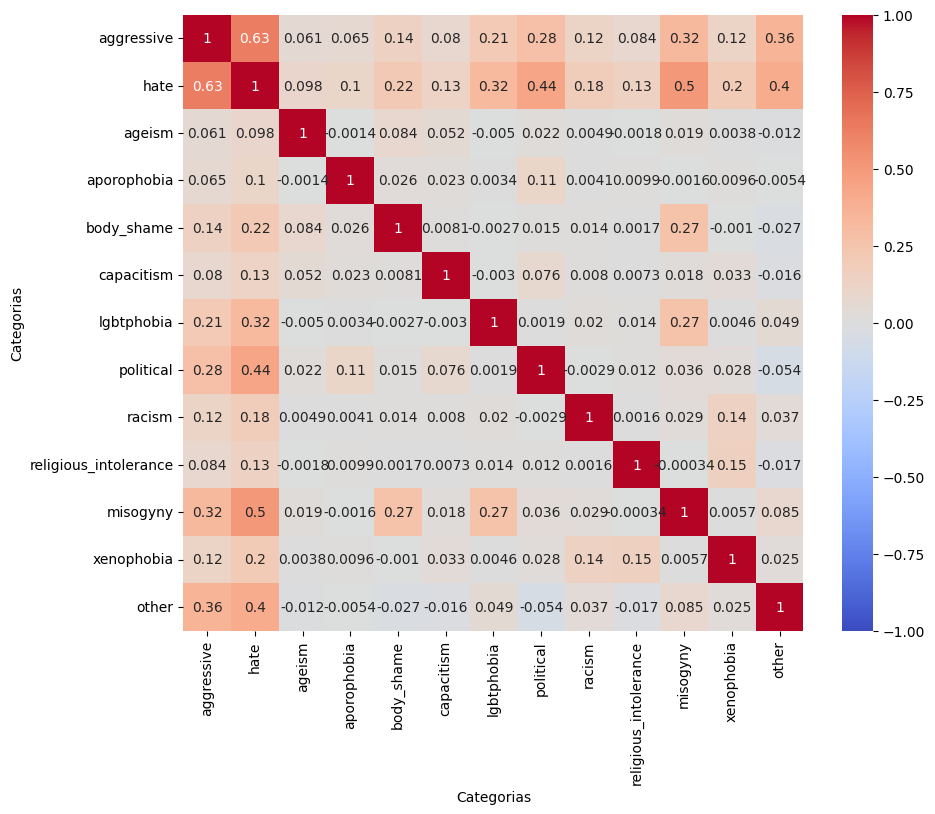

In [31]:
matriz_corr_multilabel = df_multilabel_frequency.corr()

plt.figure(figsize=(10, 8))

sns.heatmap(matriz_corr_multilabel, annot=True, cmap="coolwarm", vmin=-1, vmax=1)

plt.xlabel("Categorias")
plt.ylabel("Categorias")

plt.show()

Ao observar a matriz obtida, é perceptível pelo espelhamento de valores em torno da diagonal principal que **"aggressive"** e **"hate"** são responsáveis por muitas assinaturas de calor, dando a entender que eles geralmente acompanham os outros rótulos. Isso é esperado, dado que são categorias mais genéricas e flexíveis.

Outros destaques são as combinações de **"body_shame"** e **"misogyny"**, além de **"misogyny"** com **"lgbtphobia"**.

Para entender a **densidade de múltiplas infrações** na mesma frase, vamos construir um gráfico de barras que mostre **quantas mensagens** possuem 0, 1, 2... rótulos simultâneos (soma dos rótulos de cada linha).

0    30936
1     6405
2     1075
3     3784
4     1356
5      110
6        2
Name: count, dtype: int64


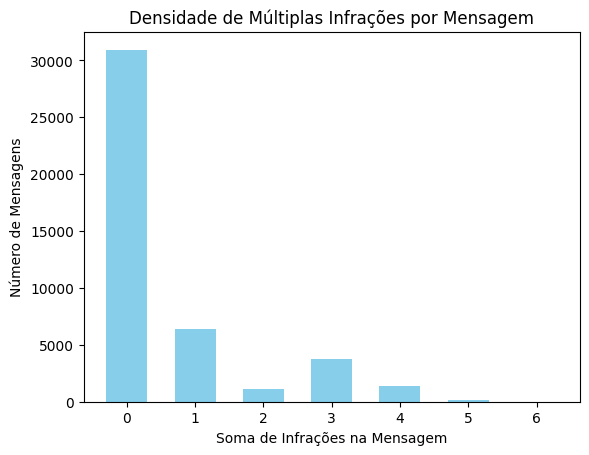

In [32]:
# Soma de infrações para cada uma das linhas
line_sum_multilabel = df_multilabel_frequency.sum(axis=1)
contagem_rotulos_multilabel = line_sum_multilabel.value_counts().sort_index()
print(contagem_rotulos_multilabel)

plt.bar(contagem_rotulos_multilabel.index.astype(str), contagem_rotulos_multilabel.values,
        color='skyblue', width=0.6)
plt.title('Densidade de Múltiplas Infrações por Mensagem')
plt.xlabel('Soma de Infrações na Mensagem')
plt.ylabel('Número de Mensagens')
plt.show()

De acordo com o gráfico de barras acima, nenhum texto ultrapassa seis rótulos (apenas 2 mensagens chegam a esse valor), e a maior concentração está em zero rótulo (30.936 mensagens sem nenhuma infração). Entre as mensagens com algum rótulo, predominam as de um rótulo (6.405), seguidas pelas de três (3.784), que superam as de dois (1.075), o que sugere uma combinação recorrente de rótulos (a verificar).

Com o objetivo de definir o hiperparâmetro `max_length` do *Tokenizer* do **BERT**, vamos plotar a distribuição da quantidade de caracteres da coluna `text`:

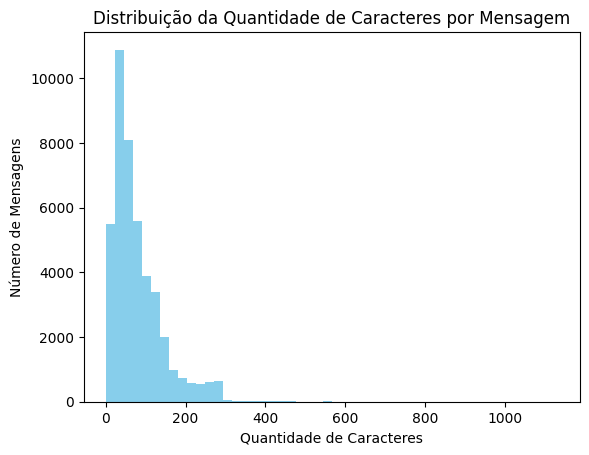

count    43668.000000
mean        79.374599
std         64.663055
min          1.000000
25%         34.000000
50%         60.000000
75%        106.000000
max       1131.000000
Name: text, dtype: float64


In [33]:
# Contagem de caracteres para cada mensagem
char_count_multilabel = df_multilabel_cleaned['text'].str.len()

plt.hist(char_count_multilabel, bins=50, color='skyblue')
plt.title('Distribuição da Quantidade de Caracteres por Mensagem')
plt.xlabel('Quantidade de Caracteres')
plt.ylabel('Número de Mensagens')
plt.show()

print(char_count_multilabel.describe())

Visualmente, a grande maioria das mensagens não ultrapassa **400 caracteres**: a média é de aproximadamente 79 caracteres, a mediana é 60 e 75% das mensagens têm até 106 caracteres. O maior texto tem 1.131 caracteres (*outlier*).

# Estruturando Modelo para Multilabel

## Fase de Peneira

Mesmo protocolo do Notebook 1 (dois rótulos): 15% do treino como validação, revocação-alvo de 0,90 para escolher o limiar e teste usado uma única vez.

In [34]:
df_multilabel_train_cleaned = df_multilabel_train.drop(columns=COLUNAS_DESCARTADAS)
df_multilabel_test_cleaned = df_multilabel_test.drop(columns=COLUNAS_DESCARTADAS)

# Colunas que representam as infrações (ignorando a coluna 'text')
colunas_crimes = ['aggressive',
                  'hate',
                  'ageism',
                  'aporophobia',
                  'body_shame',
                  'capacitism',
                  'lgbtphobia',
                  'political',
                  'racism',
                  'religious_intolerance',
                  'misogyny',
                  'xenophobia',
                  'other']

# Coluna 'label' (exigida pelo Hugging Face): .max(axis=1) varre a linha
# horizontalmente; se encontrar algum 1, o label vira 1 (qualquer um dos 13 rótulos).
df_multilabel_train_cleaned['label'] = df_multilabel_train_cleaned[colunas_crimes].max(axis=1)
df_multilabel_test_cleaned['label'] = df_multilabel_test_cleaned[colunas_crimes].max(axis=1)

X_train = df_multilabel_train_cleaned['text']
y_train = df_multilabel_train_cleaned['label']
X_test = df_multilabel_test_cleaned['text']
y_test = df_multilabel_test_cleaned['label']

In [35]:
# 1. Pipeline para redes sociais
pipeline_svm_otimizado = Pipeline([
    # Combinação de N-gramas de palavras e poda de ruído
    ('tfidf', TfidfVectorizer(
        max_features=20000,
        analyzer='word',      # Pode testar 'char_wb' se a ofuscação for severa
        ngram_range=(1, 3),   # Captura expressões curtas (ex: "filho da p...")
        min_df=3,             # Poda termos raros (ruído)
        max_df=0.85           # Poda termos ubíquos (excesso)
    )),

    # LinearSVC com margem suavizada (C=0.5) envolto no calibrador de probabilidades
    ('classificador_calibrado', CalibratedClassifierCV(
        estimator=LinearSVC(C=0.5, class_weight='balanced', random_state=SEED, max_iter=3000),
        method='isotonic',
        cv=5                  # Validação cruzada interna para calibrar as probabilidades
    ))
])

# 2. Validação (15% do treino) para escolher o limiar
df_sub, df_val = train_test_split(df_multilabel_train_cleaned, test_size=0.15,
                                  stratify=df_multilabel_train_cleaned['label'], random_state=SEED)
print("Treinando o filtro SVM na parte de treino (85%)...")
pipeline_svm_otimizado.fit(df_sub['text'], df_sub['label'])
p_val = pipeline_svm_otimizado.predict_proba(df_val['text'])[:, 1]

# Maior limiar que ainda mantém revocação >= alvo na VALIDAÇÃO
alvo = 0.90
pos = (df_val['label'].values == 1)
candidatos = [t for t in np.arange(0.05, 0.60, 0.01)
              if ((p_val >= t) & pos).sum() / pos.sum() >= alvo]
if not candidatos:
    print("⚠️ Nenhum limiar atingiu a revocação-alvo na validação; usando o mínimo da grade.")
limiar_svm_calibrado = max(candidatos) if candidatos else 0.05
print(f"Limiar escolhido na validação: {limiar_svm_calibrado:.2f}")

# 3. Reajuste no treino completo e predição no teste (usado uma única vez)
print("Reajustando o filtro SVM no treino completo...")
pipeline_svm_otimizado.fit(X_train, y_train)
probabilidade_crime_svm = pipeline_svm_otimizado.predict_proba(X_test)[:, 1]
y_pred_svm_otimizado = (probabilidade_crime_svm >= limiar_svm_calibrado).astype(int)

# 4. Avaliação
print(f"\nRelatório SVM (limiar de probabilidade: {limiar_svm_calibrado:.2f}):")
print(classification_report(y_test, y_pred_svm_otimizado, target_names=["Benigno", "Crime"]))

Treinando o filtro SVM na parte de treino (85%)...
Limiar escolhido na validação: 0.15
Reajustando o filtro SVM no treino completo...

Relatório SVM (limiar de probabilidade: 0.15):
              precision    recall  f1-score   support

     Benigno       0.92      0.54      0.68      6166
       Crime       0.45      0.89      0.60      2568

    accuracy                           0.64      8734
   macro avg       0.69      0.72      0.64      8734
weighted avg       0.78      0.64      0.66      8734



### Classificação das treze categorias, pós-filtro

In [36]:
# 1. Separar as duas classes no conjunto de TREINO (já sem os 15% reservados para validação)
df_crimes_treino = df_sub[df_sub['label'] == 1]
df_benignos_treino = df_sub[df_sub['label'] == 0]

# 2. Amostra aleatória de benignos do exato tamanho dos crimes (proporção 1:1)
df_benignos_amostra = df_benignos_treino.sample(n=len(df_crimes_treino), random_state=SEED)

# 3. Mesclar e embaralhar o conjunto de treino da Fase 2
df_fase2_train = pd.concat([df_crimes_treino, df_benignos_amostra]).sample(frac=1, random_state=SEED).copy()

# Validação: textos de validação que o SVM (treinado em 85%) deixou passar
df_fase2_val = df_val[p_val >= limiar_svm_calibrado].copy()

# Teste: tudo o que o SVM deixou passar (usado uma única vez, na avaliação final)
indices_suspeitos_teste = (y_pred_svm_otimizado == 1)
df_fase2_test = df_multilabel_test_cleaned[indices_suspeitos_teste].copy()

print(f"Textos para treino (crimes + benignos amostrados): {len(df_fase2_train)}")
print(f"Textos para validação (aprovados pelo SVM): {len(df_fase2_val)}")
print(f"Textos para teste (aprovados pelo SVM): {len(df_fase2_test)}")

# Rótulos multirrótulo (lista de floats): benigno = vetor de zeros
for d in (df_fase2_train, df_fase2_val, df_fase2_test):
    d['labels'] = d[colunas_crimes].values.astype(float).tolist()

Textos para treino (crimes + benignos amostrados): 17278
Textos para validação (aprovados pelo SVM): 3208
Textos para teste (aprovados pelo SVM): 5137


In [37]:
# Peso por rótulo = negativos / positivos no treino da Fase 2 (limitado para evitar instabilidade)
Y_tr = np.array(df_fase2_train['labels'].tolist())
pos = Y_tr.sum(axis=0)
neg = len(Y_tr) - pos
pos_weight = torch.tensor(np.clip(neg / np.maximum(pos, 1), 1, 50), dtype=torch.float).to(device)

class WeightedBCETrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        loss = torch.nn.BCEWithLogitsLoss(pos_weight=pos_weight)(outputs.logits, labels)
        return (loss, outputs) if return_outputs else loss

In [38]:
# O BERT usa a coluna 'text' bruta (com pontuação e conectivos).
# O padding é feito dinamicamente por lote (DataCollatorWithPadding),
# em vez de preencher todos os textos até max_length.
def tokenizar(exemplos):
    return tokenizer_bert(exemplos['text'], truncation=True, max_length=128)

dataset_fase2_train = Dataset.from_pandas(df_fase2_train[['text', 'labels']], preserve_index=False)
dataset_fase2_val = Dataset.from_pandas(df_fase2_val[['text', 'labels']], preserve_index=False)
dataset_fase2_test = Dataset.from_pandas(df_fase2_test[['text', 'labels']], preserve_index=False)

dataset_fase2_train = dataset_fase2_train.map(tokenizar, batched=True)
dataset_fase2_val = dataset_fase2_val.map(tokenizar, batched=True)
dataset_fase2_test = dataset_fase2_test.map(tokenizar, batched=True)

Map:   0%|          | 0/17278 [00:00<?, ? examples/s]

Map:   0%|          | 0/3208 [00:00<?, ? examples/s]

Map:   0%|          | 0/5137 [00:00<?, ? examples/s]

In [39]:
# Arquitetura multirrótulo: sigmoide independente por categoria e
# Entropia Cruzada Binária ponderada (pos_weight por rótulo; ver WeightedBCETrainer).
model_fase2 = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(colunas_crimes),
    problem_type="multi_label_classification"
).to(device)

args_fase2 = TrainingArguments(
    output_dir="./resultados_fase2_multilabel",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    num_train_epochs=5,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    seed=SEED,
    report_to="none",
)

trainer_fase2 = WeightedBCETrainer(
    model=model_fase2,
    args=args_fase2,
    train_dataset=dataset_fase2_train,
    eval_dataset=dataset_fase2_val,   # validação em cascata (o teste só entra no predict final)
    data_collator=DataCollatorWithPadding(tokenizer=tokenizer_bert),
    callbacks=[EarlyStoppingCallback(early_stopping_patience=1)]
)

print("\nIniciando o treinamento multirrótulo do especialista (Fase 2)...")
trainer_fase2.train()

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: neuralmind/bert-base-portuguese-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from th


Iniciando o treinamento multirrótulo do especialista (Fase 2)...


Epoch,Training Loss,Validation Loss
1,0.611444,0.493231
2,0.457598,0.459095
3,0.314917,0.475954


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=3240, training_loss=0.48702338183367694, metrics={'train_runtime': 720.2166, 'train_samples_per_second': 71.97, 'train_steps_per_second': 4.499, 'total_flos': 1900561759159884.0, 'train_loss': 0.48702338183367694, 'epoch': 3.0})

In [40]:
# Avaliação e extração das métricas (multirrótulo)
print("\nGerando predições na Fase 2...")
resultados_fase2 = trainer_fase2.predict(dataset_fase2_test)

# Sigmoide: probabilidades independentes (0.0 a 1.0) para cada coluna
probabilidades_fase2 = torch.sigmoid(torch.tensor(resultados_fase2.predictions)).numpy()
y_true_fase2 = resultados_fase2.label_ids.astype(int)

limiar_fase2 = 0.5
y_pred_fase2 = np.where(probabilidades_fase2 >= limiar_fase2, 1, 0)

# zero_division=0 apenas silencia os avisos das mensagens benignas ([0, 0] reais e preditas);
# os valores do relatório não mudam.
print("\nRelatório de Classificação Final em Cascata:")
print(classification_report(y_true_fase2, y_pred_fase2, target_names=colunas_crimes, zero_division=0))


Gerando predições na Fase 2...



Relatório de Classificação Final em Cascata:
                       precision    recall  f1-score   support

           aggressive       0.59      0.86      0.70      2052
                 hate       0.48      0.79      0.60       965
               ageism       0.00      0.00      0.00        11
          aporophobia       0.17      0.58      0.26        12
           body_shame       0.24      0.62      0.35        60
           capacitism       0.05      0.20      0.07        10
           lgbtphobia       0.53      0.88      0.66       134
            political       0.39      0.73      0.51       208
               racism       0.20      0.71      0.31        51
religious_intolerance       0.15      0.77      0.25        13
             misogyny       0.36      0.85      0.51       303
           xenophobia       0.28      0.69      0.40        70
                other       0.34      0.87      0.49       804

            micro avg       0.45      0.83      0.59      4693
       

## Exportar resultados

Grava as previsões da cascata (teste completo, ponta a ponta) para o Notebook 3. Para persistir entre sessões do Colab, aponte `PASTA_RESULTADOS` para uma pasta do Google Drive.

In [41]:
import os
from google.colab import drive

# 1. Monta o Google Drive no ambiente do Colab
# (Se você já montou em uma célula anterior nesta mesma sessão, pode remover ou comentar estas 2 linhas)
drive.mount('/content/drive')

# 2. Define o caminho dentro do seu "Meu Drive"
# Altere "resultados" caso queira salvar dentro de outra subpasta (ex: "/content/drive/MyDrive/Meu_Projeto/resultados")
PASTA_RESULTADOS = "/content/drive/MyDrive/Resultados_crimescib"
os.makedirs(PASTA_RESULTADOS, exist_ok=True)

Y_total = df_multilabel_test_cleaned[colunas_crimes].values
y_pred_casc = np.zeros_like(Y_total)
y_pred_casc[indices_suspeitos_teste] = y_pred_fase2          # barrado pelo SVM = 0

caminho_arquivo = os.path.join(PASTA_RESULTADOS, "cascata_13rotulos.npz")
np.savez_compressed(caminho_arquivo,
                    Y_total=Y_total,
                    y_pred_casc=y_pred_casc,
                    idx_val=df_val.index.values,
                    limiar_svm_calibrado=limiar_svm_calibrado)

print("Resultados salvos em:", caminho_arquivo)

Mounted at /content/drive
Resultados salvos em: /content/drive/MyDrive/Resultados_crimescib/cascata_13rotulos.npz


## Análises do modelo: ROC-AUC

In [42]:
from sklearn.metrics import roc_auc_score, average_precision_score, RocCurveDisplay

def tabela_auc(Y, P, nomes):
    linhas = []
    for j, nome in enumerate(nomes):
        s = int(Y[:, j].sum())
        if s == 0 or s == len(Y):   # AUC não é definida com uma só classe
            linhas.append({'Rótulo': nome, 'ROC-AUC': np.nan, 'PR-AUC': np.nan, 'Suporte': s})
        else:
            linhas.append({'Rótulo': nome, 'ROC-AUC': roc_auc_score(Y[:, j], P[:, j]),
                           'PR-AUC': average_precision_score(Y[:, j], P[:, j]), 'Suporte': s})
    df = pd.DataFrame(linhas).set_index('Rótulo')
    df.loc['macro'] = [df['ROC-AUC'].mean(), df['PR-AUC'].mean(), df['Suporte'].sum()]
    df.loc['micro'] = [roc_auc_score(Y, P, average='micro'),
                       average_precision_score(Y, P, average='micro'), df.loc['macro', 'Suporte']]
    return df

def estilizar_auc(df, titulo):
    return (df.style.set_caption(titulo)
              .format({'ROC-AUC': '{:.2f}', 'PR-AUC': '{:.2f}', 'Suporte': '{:.0f}'}, na_rep='–')
              .background_gradient(cmap='Blues', subset=['ROC-AUC', 'PR-AUC'], vmin=0, vmax=1))

passou = indices_suspeitos_teste
Y_total = df_multilabel_test_cleaned[colunas_crimes].values
P_total = np.zeros(Y_total.shape); P_total[passou] = probabilidades_fase2

display(estilizar_auc(tabela_auc(y_true_fase2, probabilidades_fase2, colunas_crimes), 'AUC (condicional ao SVM)'))
display(estilizar_auc(tabela_auc(Y_total, P_total, colunas_crimes), 'AUC (ponta a ponta)'))

,ROC-AUC,PR-AUC,Suporte
Rótulo,,,
aggressive,0.80,0.70,2052
hate,0.87,0.61,965
ageism,0.74,0.01,11
aporophobia,0.95,0.40,12
body_shame,0.95,0.38,60
capacitism,0.80,0.02,10
lgbtphobia,0.97,0.68,134
political,0.93,0.44,208
racism,0.95,0.32,51


,ROC-AUC,PR-AUC,Suporte
Rótulo,,,
aggressive,0.84,0.66,2280
hate,0.87,0.57,1050
ageism,0.79,0.01,12
aporophobia,0.86,0.35,14
body_shame,0.93,0.37,63
capacitism,0.82,0.02,11
lgbtphobia,0.91,0.62,149
political,0.89,0.40,230
racism,0.90,0.29,56


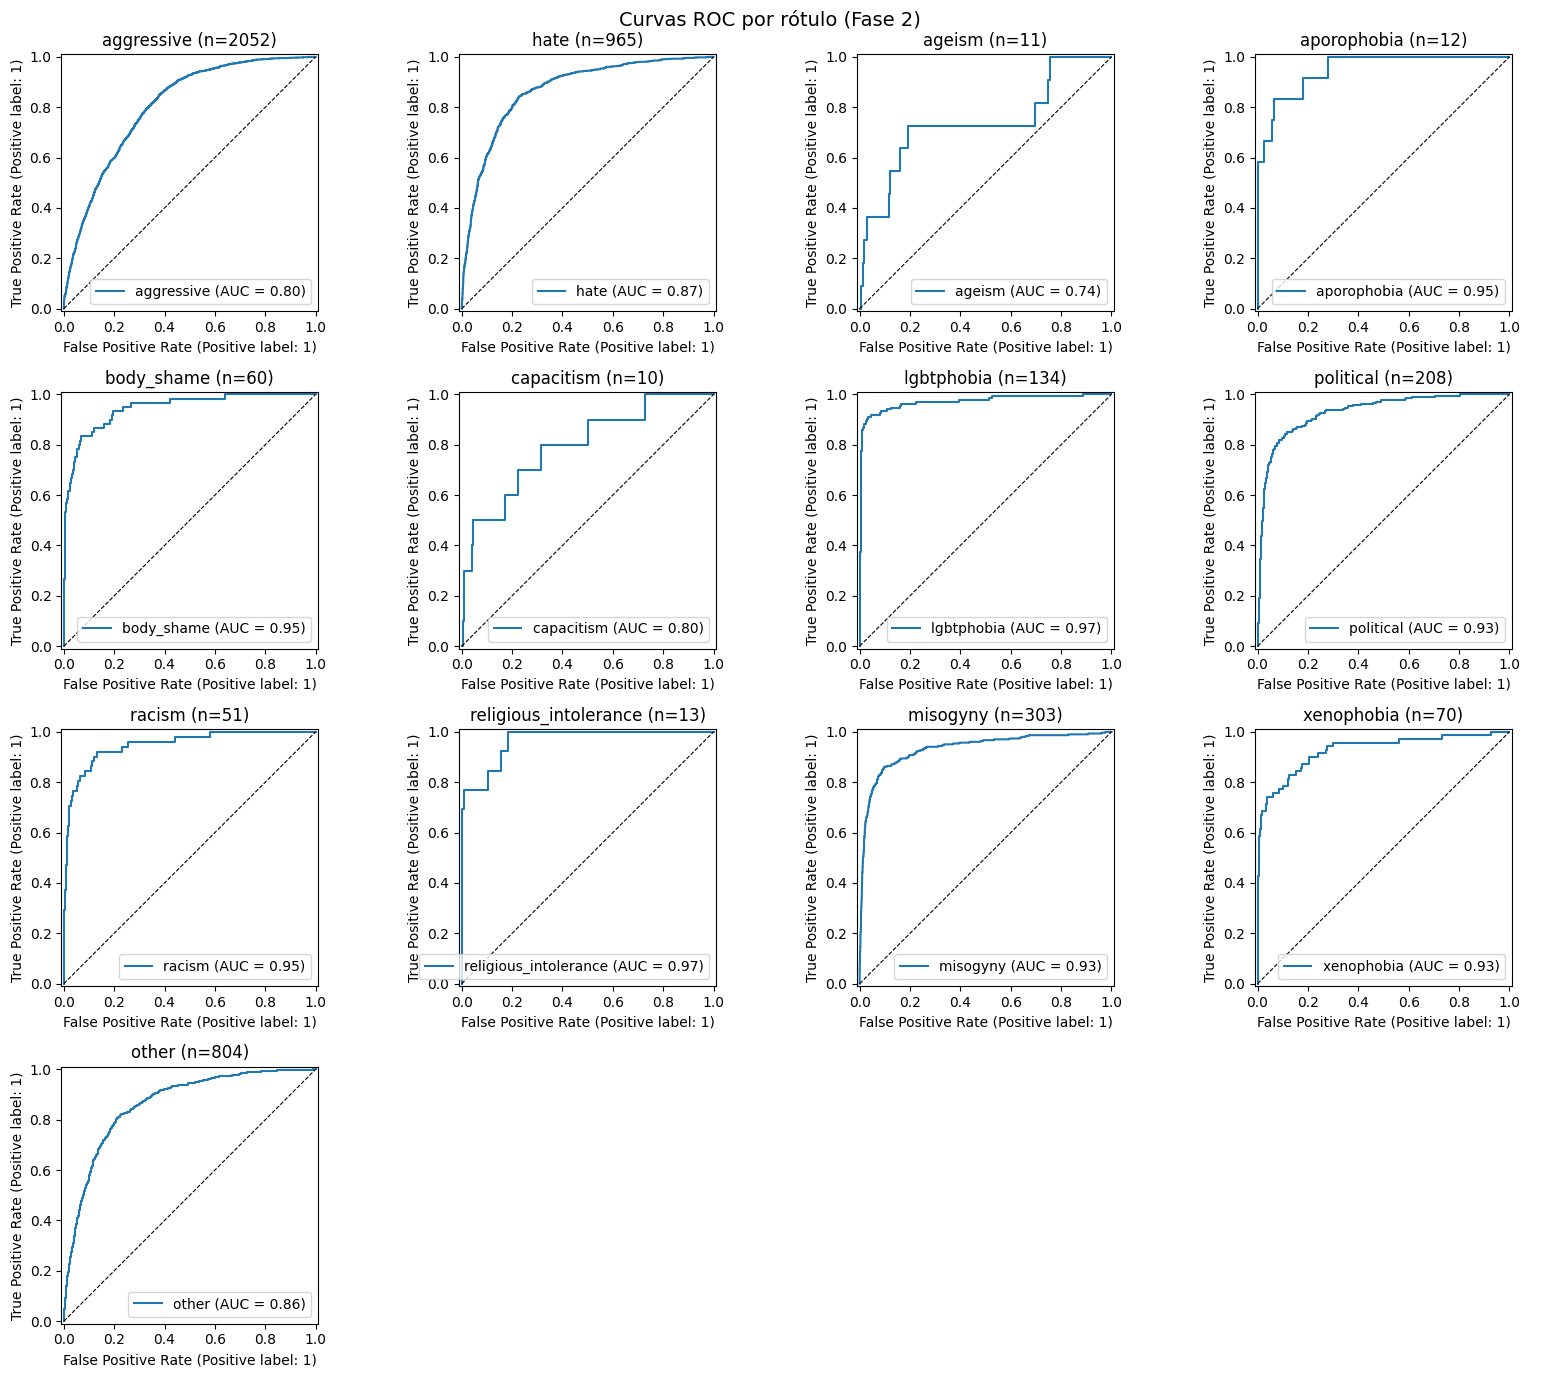

In [43]:
def plotar_roc(Y, P, nomes, titulo):
    fig, axes = plt.subplots(4, 4, figsize=(16, 14)); axes = axes.ravel()
    for j, nome in enumerate(nomes):
        RocCurveDisplay.from_predictions(Y[:, j], P[:, j], ax=axes[j], name=nome)
        axes[j].plot([0, 1], [0, 1], 'k--', lw=0.8)
        axes[j].set_title(f"{nome} (n={int(Y[:, j].sum())})")
    for ax in axes[len(nomes):]: ax.axis('off')
    fig.suptitle(titulo, fontsize=14); plt.tight_layout(); plt.show()

plotar_roc(y_true_fase2, probabilidades_fase2, colunas_crimes, 'Curvas ROC por rótulo (Fase 2)')

## Matrizes de confusão

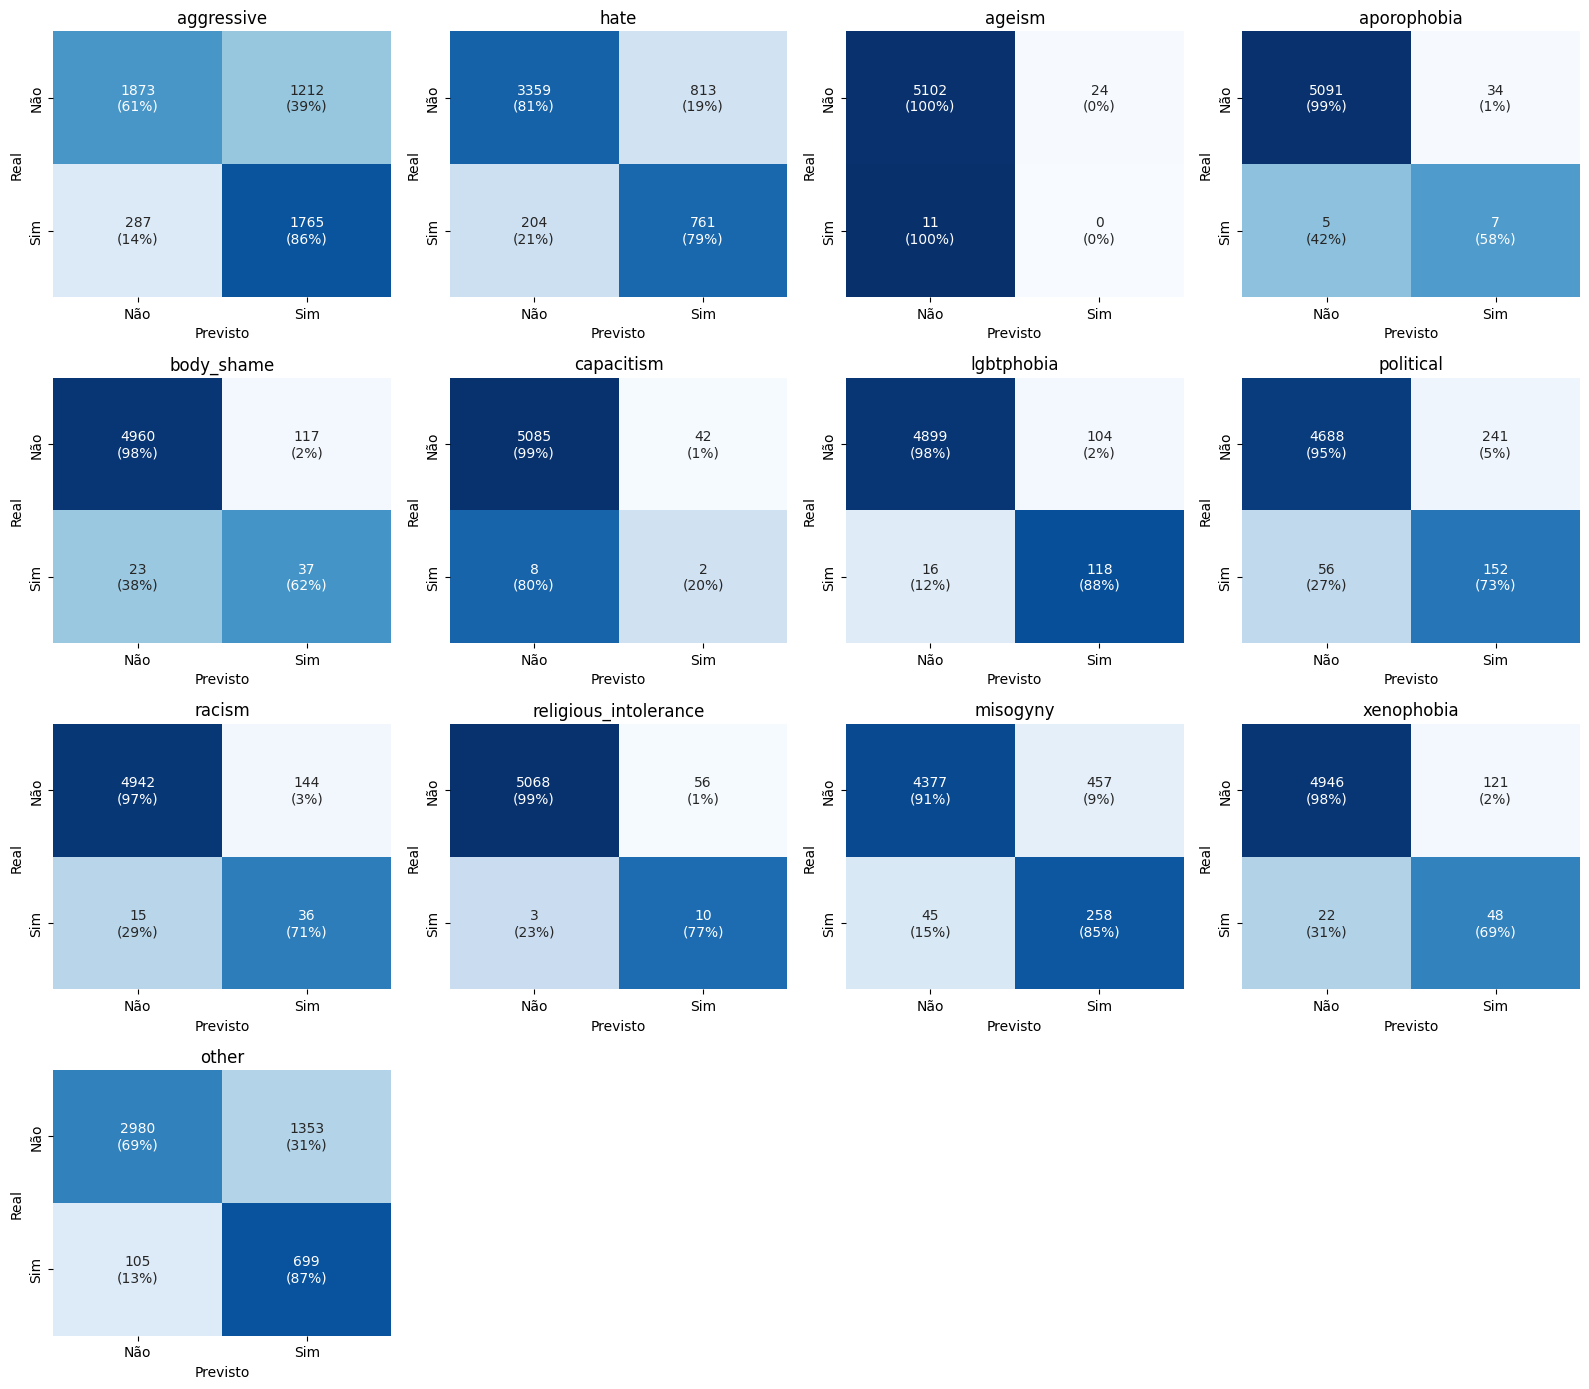

In [44]:
from sklearn.metrics import multilabel_confusion_matrix

def plotar_confusoes(Y, Ypred, nomes):
    mcm = multilabel_confusion_matrix(Y, Ypred)
    fig, axes = plt.subplots(4, 4, figsize=(16, 14)); axes = axes.ravel()
    for ax, m, nome in zip(axes, mcm, nomes):
        pct = m / np.maximum(m.sum(axis=1, keepdims=True), 1)
        anot = np.array([[f"{m[i, j]}\n({pct[i, j]:.0%})" for j in range(2)] for i in range(2)])
        sns.heatmap(pct, annot=anot, fmt='', cmap='Blues', vmin=0, vmax=1, cbar=False, ax=ax,
                    xticklabels=['Não', 'Sim'], yticklabels=['Não', 'Sim'])
        ax.set_title(nome); ax.set_xlabel('Previsto'); ax.set_ylabel('Real')
    for ax in axes[len(nomes):]: ax.axis('off')
    plt.tight_layout(); plt.show()

plotar_confusoes(y_true_fase2, y_pred_fase2, colunas_crimes)


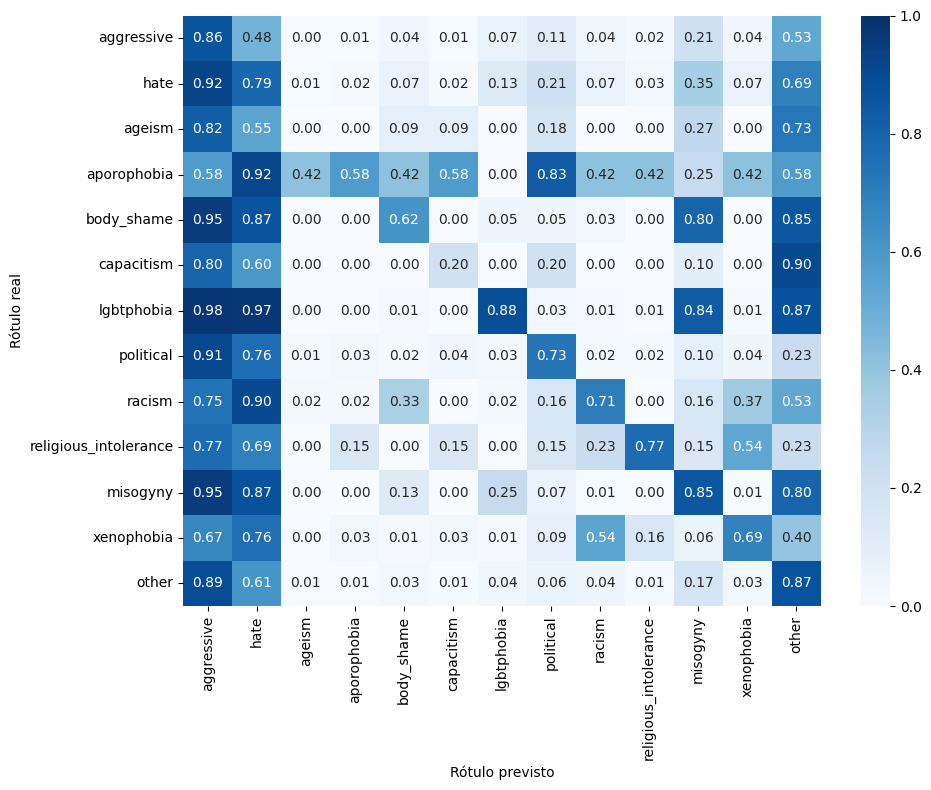

In [45]:
def plotar_confusao_entre_rotulos(Y, Ypred, nomes):
    C = Y.T @ Ypred                                   # C[i, j]: rótulo real i, rótulo previsto j
    Cn = C / np.maximum(Y.sum(axis=0)[:, None], 1)    # normalizado pelo suporte do rótulo real
    plt.figure(figsize=(10, 8))
    sns.heatmap(pd.DataFrame(Cn, index=nomes, columns=nomes), annot=True, fmt='.2f',
                cmap='Blues', vmin=0, vmax=1)
    plt.xlabel('Rótulo previsto'); plt.ylabel('Rótulo real'); plt.tight_layout(); plt.show()

plotar_confusao_entre_rotulos(y_true_fase2, y_pred_fase2, colunas_crimes)

## Pesos de *self-attention*

O modelo é recarregado com atenção `eager`, necessária para o PyTorch devolver os pesos. A atenção é uma evidência indicativa, e não uma explicação causal da decisão.

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Rótulo real: racism


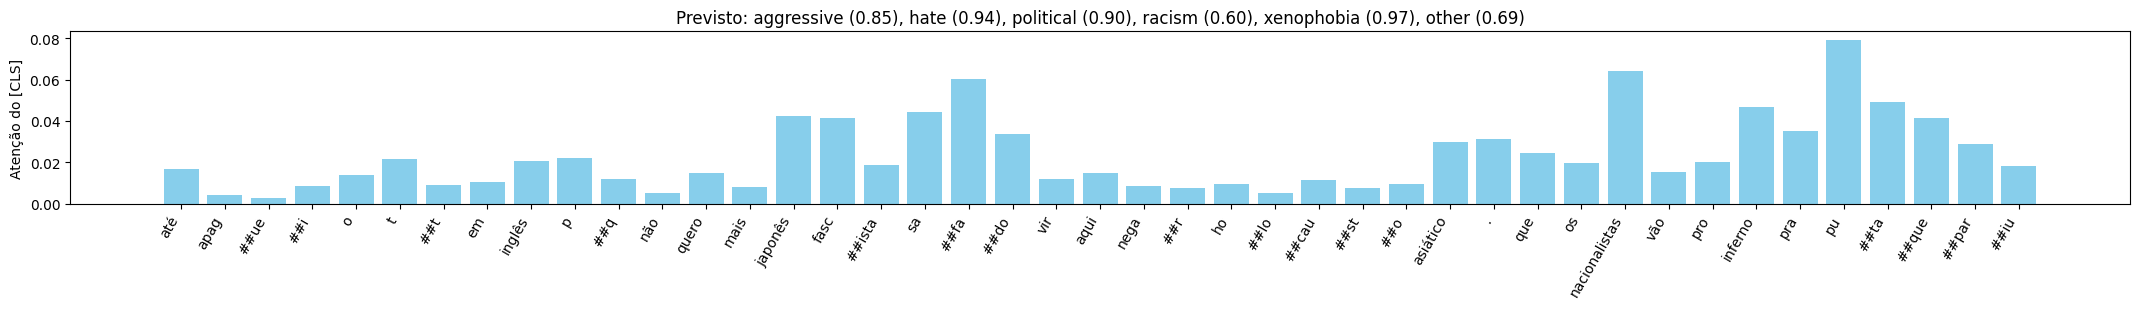

Rótulo real: misogyny


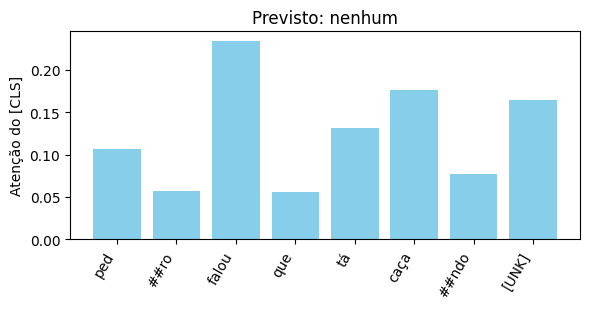

Rótulo real: lgbtphobia


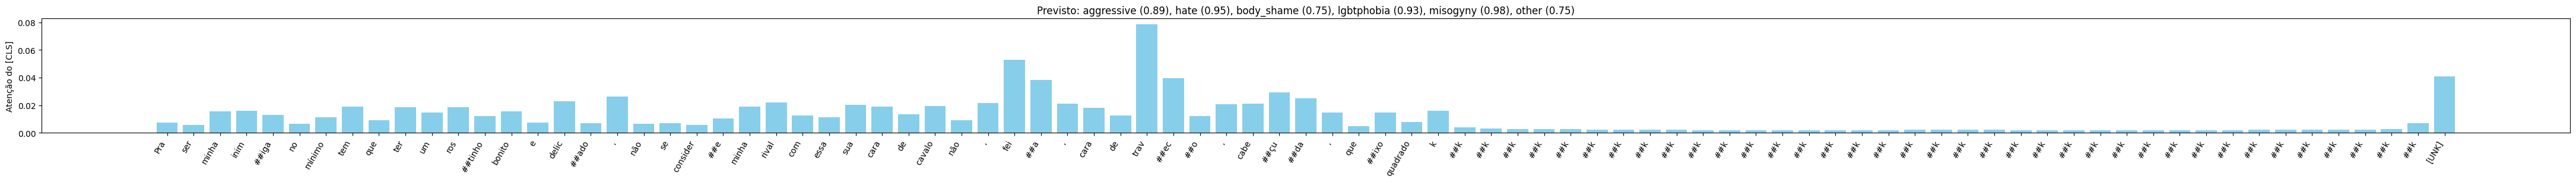

Rótulo real: religious_intolerance


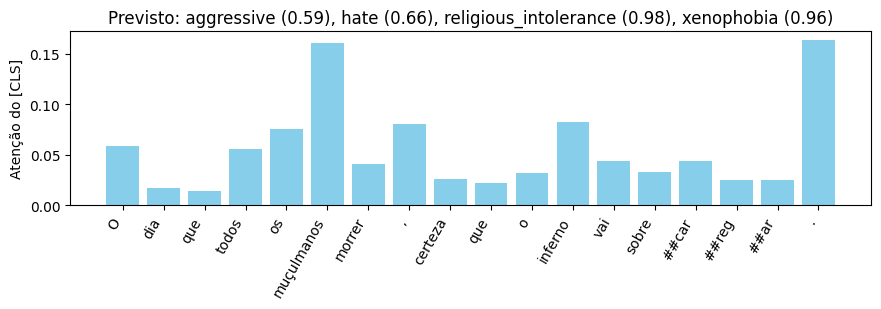

In [46]:
# Pesos de self-attention do BERT: linha do [CLS] na última camada, média das cabeças
trainer_fase2.save_model("modelo_fase2_final")
model_attn = AutoModelForSequenceClassification.from_pretrained(
    "modelo_fase2_final", attn_implementation="eager").to(device).eval()   # "eager" é necessário para devolver os pesos

@torch.no_grad()
def atencao_cls(texto, camada=-1):
    enc = tokenizer_bert(texto, return_tensors='pt', truncation=True, max_length=128).to(device)
    out = model_attn(**enc, output_attentions=True)
    pesos = out.attentions[camada][0].mean(dim=0)[0].cpu().numpy()          # [CLS] -> tokens
    tokens = tokenizer_bert.convert_ids_to_tokens(enc['input_ids'][0].tolist())
    manter = [t not in ('[CLS]', '[SEP]') for t in tokens]                   # ignora tokens especiais
    pesos = np.array([w for w, k in zip(pesos, manter) if k]); pesos = pesos / pesos.sum()
    tokens = [t for t, k in zip(tokens, manter) if k]
    return tokens, pesos, torch.sigmoid(out.logits)[0].cpu().numpy()

def plotar_atencao(texto, camada=-1, limiar=0.5):
    tokens, pesos, probs = atencao_cls(texto, camada)
    plt.figure(figsize=(max(6, 0.5 * len(tokens)), 3.2))
    plt.bar(range(len(tokens)), pesos, color='skyblue')
    plt.xticks(range(len(tokens)), tokens, rotation=60, ha='right')
    plt.ylabel('Atenção do [CLS]')
    prev = [f"{n} ({p:.2f})" for n, p in zip(colunas_crimes, probs) if p >= limiar]
    plt.title('Previsto: ' + (', '.join(prev) or 'nenhum')); plt.tight_layout(); plt.show()

# Um exemplo real de cada categoria específica (entre os textos aprovados pelo SVM no teste)
for rotulo in ['racism', 'misogyny', 'lgbtphobia', 'religious_intolerance']:
    achados = df_fase2_test.loc[df_fase2_test[rotulo] == 1, 'text']
    if len(achados):
        print(f"Rótulo real: {rotulo}")
        plotar_atencao(achados.iloc[0])

## Ablação da perda ponderada (experimento longo)

Treina a Fase 2 dez vezes (5 sementes, com e sem `pos_weight`) com 3 épocas fixas e sem usar o teste para seleção. Leva mais de 2 horas; rode por último.

In [47]:
import gc
from scipy import stats
from sklearn.metrics import f1_score

RARAS = ['ageism', 'aporophobia', 'capacitism', 'religious_intolerance']
idx_raras = [colunas_crimes.index(c) for c in RARAS]

def treinar_e_prever(seed, ponderada, epocas=3):
    set_seed(seed)
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=len(colunas_crimes), problem_type="multi_label_classification").to(device)
    args = TrainingArguments(output_dir=f"./abl_{seed}_{int(ponderada)}", num_train_epochs=epocas,
                             learning_rate=2e-5, per_device_train_batch_size=16, weight_decay=0.01,
                             save_strategy="no", eval_strategy="no", seed=seed, report_to="none")
    Classe = WeightedBCETrainer if ponderada else Trainer
    trainer = Classe(model=model, args=args, train_dataset=dataset_fase2_train,
                     data_collator=DataCollatorWithPadding(tokenizer=tokenizer_bert))
    trainer.train()
    logits = trainer.predict(dataset_fase2_test).predictions
    y_pred = (1 / (1 + np.exp(-logits)) >= 0.5).astype(int)
    del model, trainer; gc.collect(); torch.cuda.empty_cache()
    return y_pred

def metricas(y_pred):
    f1 = f1_score(y_true_fase2, y_pred, average=None, zero_division=0)
    return f1.mean(), f1[idx_raras].mean()

seeds = [1, 2, 3, 4, 5]
preds = {p: {s: treinar_e_prever(s, p) for s in seeds} for p in [False, True]}   # 10 treinos
a = np.array([metricas(preds[False][s]) for s in seeds])   # sem peso
b = np.array([metricas(preds[True][s]) for s in seeds])    # com peso

for j, nome in enumerate(['F1 macro (13 rótulos)', 'F1 macro (4 raras)']):
    t, p = stats.ttest_rel(b[:, j], a[:, j])
    print(f"{nome}: sem peso {a[:, j].mean():.3f}±{a[:, j].std(ddof=1):.3f} | "
          f"com peso {b[:, j].mean():.3f}±{b[:, j].std(ddof=1):.3f} | t={t:.2f}, p={p:.4f}")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: neuralmind/bert-base-portuguese-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from th

Step,Training Loss
500,0.206536
1000,0.145259
1500,0.122381
2000,0.113043
2500,0.100641
3000,0.092494


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: neuralmind/bert-base-portuguese-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from th

Step,Training Loss
500,0.211192
1000,0.144270
1500,0.124725
2000,0.112716
2500,0.100621
3000,0.092043


... (21 outputs left out)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: neuralmind/bert-base-portuguese-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from th

Step,Training Loss
500,0.789961
1000,0.588142
1500,0.490755
2000,0.467778
2500,0.381547
3000,0.326305


F1 macro (13 rótulos): sem peso 0.324±0.027 | com peso 0.411±0.011 | t=5.36, p=0.0059
F1 macro (4 raras): sem peso 0.000±0.000 | com peso 0.159±0.026 | t=13.66, p=0.0002


In [48]:
def mcnemar_exato(acerto_a, acerto_b):
    b01 = int(((acerto_a == 1) & (acerto_b == 0)).sum())   # só A acerta
    c01 = int(((acerto_a == 0) & (acerto_b == 1)).sum())   # só B acerta
    p = 1.0 if b01 + c01 == 0 else stats.binomtest(b01, b01 + c01, 0.5).pvalue
    return b01, c01, p

def holm(p):
    p = np.asarray(p, float); m = len(p); aj = np.empty(m); atual = 0
    for rank, i in enumerate(np.argsort(p)):
        atual = max(atual, (m - rank) * p[i]); aj[i] = min(1, atual)
    return aj

def mcnemar_por_rotulo(Y, pred_a, pred_b, nomes, sobre='positivos'):
    alvo = 1 if sobre == 'positivos' else 0
    linhas = []
    for j, nome in enumerate(nomes):
        m = Y[:, j] == alvo
        b01, c01, p = mcnemar_exato((pred_a[m, j] == Y[m, j]).astype(int),
                                    (pred_b[m, j] == Y[m, j]).astype(int))
        linhas.append({'Rótulo': nome, 'n': int(m.sum()), 'só A acerta': b01, 'só B acerta': c01, 'p': p})
    df = pd.DataFrame(linhas).set_index('Rótulo')
    df['p (Holm)'] = holm(df['p'].values)
    return df

# A = BCE comum, B = BCE ponderada (mesma semente, mesmos textos)
display(mcnemar_por_rotulo(y_true_fase2, preds[False][1], preds[True][1], colunas_crimes, 'positivos'))
display(mcnemar_por_rotulo(y_true_fase2, preds[False][1], preds[True][1], colunas_crimes, 'negativos'))

,n,só A acerta,só B acerta,p,p (Holm)
Rótulo,,,,,
aggressive,2052,153,90,6.387856e-05,3.193928e-04
hate,965,11,151,1.316178e-32,1.579413e-31
ageism,11,0,2,5.000000e-01,1.000000e+00
aporophobia,12,0,7,1.562500e-02,4.687500e-02
body_shame,60,0,42,4.547474e-13,3.637979e-12
capacitism,10,0,2,5.000000e-01,1.000000e+00
lgbtphobia,134,0,28,7.450581e-09,4.470348e-08
political,208,0,54,1.110223e-16,1.110223e-15
racism,51,0,39,3.637979e-12,2.546585e-11


,n,só A acerta,só B acerta,p,p (Holm)
Rótulo,,,,,
aggressive,3085,260,154,2.128712e-07,2.128712e-07
hate,4172,366,55,1.848545e-57,2.033400e-56
ageism,5126,42,0,4.547474e-13,1.364242e-12
aporophobia,5125,33,0,2.328306e-10,4.656613e-10
body_shame,5077,103,0,1.972152e-31,1.380507e-30
capacitism,5127,55,0,5.551115e-17,2.775558e-16
lgbtphobia,5003,109,2,4.789403e-30,2.873642e-29
political,4929,168,7,3.846779e-41,3.462101e-40
racism,5086,136,0,2.295887e-41,2.295887e-40
